In [30]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd
from scipy import stats

In [4]:
from google.colab import files

arquivos_enviados = files.upload()

print("\nArquivos enviados:")
for nome in arquivos_enviados:
    print(nome)


Saving LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv to LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv
Saving LSDS-130_microCT_Cahill_RR1_MicroCt_Data_SUBMITTED.xlsx to LSDS-130_microCT_Cahill_RR1_MicroCt_Data_SUBMITTED.xlsx
Saving LSDS-130_microCT_micro_computed_tomography_Data_Dictionary.csv to LSDS-130_microCT_micro_computed_tomography_Data_Dictionary.csv

Arquivos enviados:
LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv
LSDS-130_microCT_Cahill_RR1_MicroCt_Data_SUBMITTED.xlsx
LSDS-130_microCT_micro_computed_tomography_Data_Dictionary.csv


In [5]:
arquivos = list(Path("/content").glob("*"))

csv_path = next(
    p for p in arquivos
    if "TRANSFORMED" in p.name.upper()
    and p.suffix.lower() == ".csv"
)

dicionario_path = next(
    p for p in arquivos
    if "DICTIONARY" in p.name.upper()
    and p.suffix.lower() == ".csv"
)

df = pd.read_csv(csv_path)
dicionario = pd.read_csv(dicionario_path)

print("Base principal:", df.shape)
print("Dicionário:", dicionario.shape)

display(df.head())
display(dicionario.head(10))


Base principal: (170, 12)
Dicionário: (37, 20)


,Sample Name,bone_area_total_area_millimeter_squared,cortical_thickness_millimeter,endosteal _perimeter_millimeter,periosteal_perimeter_millimeter,bone_volume_total_volume_millimeter_cubed,connectivity_density_per_millimeter_cubed,degree_of_anistropy,trabecular_number_per_millimeter,trabecular_bone_pattern_factor,trabecular_separation_millimeter,trabecular_thickness_millimeter
0,RR1_BSL_M1_CorticalFemur,51.4835,0.208846,3.734664,5.227529,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RR1_BSL_M2_CorticalFemur,54.2758,0.221782,3.660836,5.229718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RR1_BSL_M3_CorticalFemur,53.8175,0.216016,3.610342,5.105272,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RR1_BSL_M4_CorticalFemur,53.6033,0.213607,3.682542,5.188130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RR1_BSL_M5_CorticalFemur,53.6267,0.206721,3.394830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Acronym,Term,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,pMOI,polar_moment_of_intertia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Imax,Maximum_moment_of_intertia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Imin,Minimum_moment_of_intertia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CSA,cortical_surface_area,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ConnD,connectivity_density,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,TRI,trabecular_thickness,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,SMI,structural_model_index,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Tb_N,trabecular_number,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Tb_Th,trabecular_thickness,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Tb_Sp,trabecular_separation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

# 1. Separar as informações dos nomes das amostras

df["grupo_codigo"] = df["Sample Name"].str.split("_").str[1]
df["animal_id"] = df["Sample Name"].str.extract(
    r"_(M\d+)_"
)
df["regiao_ossea"] = df["Sample Name"].str.extract(
    r"_(CorticalFemur|DistalFemur|FemoralHead|FemoralNeck|Vertebrae)$"
)

print("Códigos de grupo encontrados:")
display(df["grupo_codigo"].value_counts(dropna=False).to_frame("quantidade"))

print("Regiões ósseas encontradas:")
display(df["regiao_ossea"].value_counts(dropna=False).to_frame("quantidade"))

print("Amostras por grupo e região:")
display(pd.crosstab(df["grupo_codigo"], df["regiao_ossea"], margins=True))

print("Animais identificados:", df["animal_id"].nunique())
print("Amostras sem região identificada:", df["regiao_ossea"].isna().sum())


Códigos de grupo encontrados:


,quantidade
grupo_codigo,
FLT,46
BSL,42
VIV,42
GC,40


Regiões ósseas encontradas:


,quantidade
regiao_ossea,
CorticalFemur,40
DistalFemur,40
Vertebrae,39
FemoralNeck,27
FemoralHead,24


Amostras por grupo e região:


regiao_ossea,CorticalFemur,DistalFemur,FemoralHead,FemoralNeck,Vertebrae,All
grupo_codigo,,,,,,
BSL,10,10,5,7,10,42
FLT,10,10,8,8,10,46
GC,10,10,5,5,10,40
VIV,10,10,6,7,9,42
All,40,40,24,27,39,170


Animais identificados: 40
Amostras sem região identificada: 0


In [7]:

# 2. Verificar quais medidas estão preenchidas

colunas_medidas = df.select_dtypes(include="number").columns

resumo_ausentes = pd.DataFrame({
    "preenchidos": df[colunas_medidas].notna().sum(),
    "ausentes": df[colunas_medidas].isna().sum(),
    "percentual_ausente": (
        df[colunas_medidas].isna().mean() * 100
    ).round(1)
})

display(resumo_ausentes.sort_values("percentual_ausente"))


,preenchidos,ausentes,percentual_ausente
bone_volume_total_volume_millimeter_cubed,103,67,39.4
trabecular_thickness_millimeter,103,67,39.4
trabecular_number_per_millimeter,102,68,40.0
degree_of_anistropy,102,68,40.0
trabecular_separation_millimeter,102,68,40.0
trabecular_bone_pattern_factor,101,69,40.6
connectivity_density_per_millimeter_cubed,98,72,42.4
cortical_thickness_millimeter,65,105,61.8
bone_area_total_area_millimeter_squared,65,105,61.8
periosteal_perimeter_millimeter,63,107,62.9


In [9]:

# Verificar a disponibilidade das medidas por grupo e região

# Selecionar as colunas numéricas automaticamente
colunas_medidas = df.select_dtypes(include="number").columns.tolist()

disponibilidade = (
    df.groupby(["grupo_codigo", "regiao_ossea"])[colunas_medidas]
      .count()
)

display(disponibilidade.T)



grupo_codigo                                        BSL              \
regiao_ossea                              CorticalFemur DistalFemur   
bone_area_total_area_millimeter_squared              10           0   
cortical_thickness_millimeter                        10           0   
endosteal _perimeter_millimeter                      10           0   
periosteal_perimeter_millimeter                       8           0   
bone_volume_total_volume_millimeter_cubed             0          10   
connectivity_density_per_millimeter_cubed             0          10   
degree_of_anistropy                                   0          10   
trabecular_number_per_millimeter                      0          10   
trabecular_bone_pattern_factor                        0          10   
trabecular_separation_millimeter                      0          10   
trabecular_thickness_millimeter                       0          10   

grupo_codigo                                                                 \
regiao_ossea                              FemoralHead FemoralNeck Vertebrae   
bone_area_total_area_millimeter_squared             0           7         0   
cortical_thickness_millimeter                       0           7         0   
endosteal _perimeter_millimeter                     0           5         0   
periosteal_perimeter_millimeter                     0           6         0   
bone_volume_total_volume_millimeter_cubed           5           0        10   
connectivity_density_per_millimeter_cubed           5           0        10   
degree_of_anistropy                                 5           0        10   
trabecular_number_per_millimeter                    5           0        10   
trabecular_bone_pattern_factor                      5           0        10   
trabecular_separation_millimeter                    5           0        10   
trabecular_thickness_millimeter                     5           0        10   

grupo_codigo                                        FLT              \
regiao_ossea                              CorticalFemur DistalFemur   
bone_area_total_area_millimeter_squared              10           0   
cortical_thickness_millimeter                        10           0   
endosteal _perimeter_millimeter                      10           0   
periosteal_perimeter_millimeter                      10           0   
bone_volume_total_volume_millimeter_cubed             0          10   
connectivity_density_per_millimeter_cubed             0           8   
degree_of_anistropy                                   0          10   
trabecular_number_per_millimeter                      0          10   
trabecular_bone_pattern_factor                        0          10   
trabecular_separation_millimeter                      0          10   
trabecular_thickness_millimeter                       0          10   

grupo_codigo                                                                 \
regiao_ossea                              FemoralHead FemoralNeck Vertebrae   
bone_area_total_area_millimeter_squared             0           8         0   
cortical_thickness_millimeter                       0           8         0   
endosteal _perimeter_millimeter                     0           8         0   
periosteal_perimeter_millimeter                     0           8         0   
bone_volume_total_volume_millimeter_cubed           8           0        10   
connectivity_density_per_millimeter_cubed           8           0        10   
degree_of_anistropy                                 8           0        10   
trabecular_number_per_millimeter                    8           0        10   
trabecular_bone_pattern_factor                      8           0        10   
trabecular_separation_millimeter                    8           0        10   
trabecular_thickness_millimeter                     8           0        10   

grupo_codigo                                         GC              \
regiao_ossea             

In [10]:

# Selecionar a região e a medida que vamos analisar

coluna = "trabecular_thickness_millimeter"

analise = df[
    df["regiao_ossea"] == "DistalFemur"
].copy()

# Resumo estatístico por grupo
resumo = (
    analise.groupby("grupo_codigo")[coluna]
    .agg(
        quantidade="count",
        media="mean",
        desvio_padrao="std",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .round(4)
)

display(resumo)


,quantidade,media,desvio_padrao,mediana,minimo,maximo
grupo_codigo,,,,,,
BSL,10,0.0443,0.0013,0.0440,0.0422,0.0463
FLT,10,0.0433,0.0012,0.0438,0.0419,0.0447
GC,10,0.0448,0.0077,0.0466,0.0265,0.0547
VIV,10,0.0451,0.0018,0.0454,0.0409,0.0468


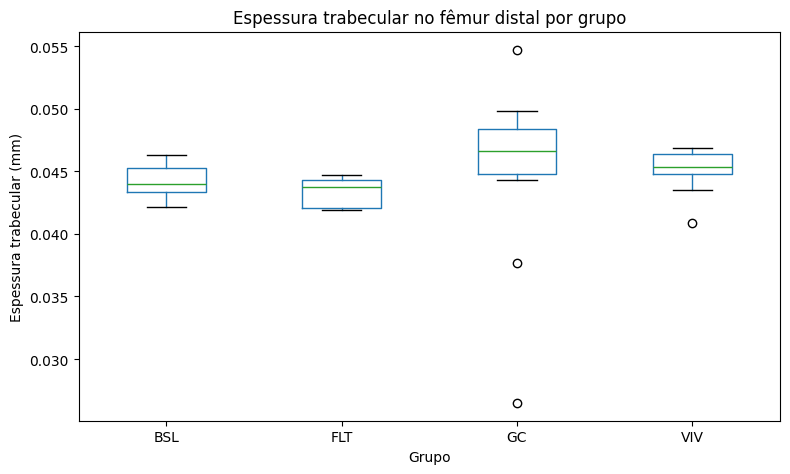

Valores individuais do grupo GC:


,Sample Name,trabecular_thickness_millimeter
100,RR1_GC_M34_DistalFemur,0.02649
103,RR1_GC_M37_DistalFemur,0.03765
99,RR1_GC_M33_DistalFemur,0.04431
101,RR1_GC_M35_DistalFemur,0.04615
104,RR1_GC_M38_DistalFemur,0.04653
105,RR1_GC_M39_DistalFemur,0.04667
97,RR1_GC_M31_DistalFemur,0.04672
98,RR1_GC_M32_DistalFemur,0.04891
106,RR1_GC_M40_DistalFemur,0.04982
102,RR1_GC_M36_DistalFemur,0.05472


In [12]:
# Manter apenas o fêmur distal e a medida selecionada
analise = df[df["regiao_ossea"] == "DistalFemur"].copy()

coluna = "trabecular_thickness_millimeter"

# Gráfico de distribuição por grupo
analise.boxplot(
    column=coluna,
    by="grupo_codigo",
    grid=False,
    figsize=(8, 5)
)

plt.title("Espessura trabecular no fêmur distal por grupo")
plt.suptitle("")
plt.xlabel("Grupo")
plt.ylabel("Espessura trabecular (mm)")
plt.tight_layout()
plt.show()

# Conferir os valores individuais do grupo GC
print("Valores individuais do grupo GC:")
display(
    analise.loc[
        analise["grupo_codigo"] == "GC",
        ["Sample Name", coluna]
    ].sort_values(coluna)
)

In [14]:
grupos = {
    nome: dados[coluna].dropna().values
    for nome, dados in analise.groupby("grupo_codigo")
}

resultado = kruskal(*grupos.values())

print(f"Estatística H: {resultado.statistic:.4f}")
print(f"Valor-p: {resultado.pvalue:.6f}")

if resultado.pvalue < 0.05:
    print("Há evidências de diferença entre pelo menos dois grupos.")
else:
    print("Não há evidências suficientes de diferença entre os grupos.")

Estatística H: 9.3320
Valor-p: 0.025188
Há evidências de diferença entre pelo menos dois grupos.


In [18]:
coluna = "trabecular_thickness_millimeter"

# Conferir se os dados estão disponíveis
print("Grupos encontrados:", analise["grupo_codigo"].unique())

grupos = {
    nome: dados[coluna].dropna().to_numpy()
    for nome, dados in analise.groupby("grupo_codigo")
}

print("Quantidade de grupos:", len(grupos))
print("Amostras por grupo:", {g: len(v) for g, v in grupos.items()})

resultados = []

for grupo_a, grupo_b in combinations(sorted(grupos.keys()), 2):
    teste = mannwhitneyu(
        grupos[grupo_a],
        grupos[grupo_b],
        alternative="two-sided"
    )

    resultados.append({
        "grupo_1": grupo_a,
        "grupo_2": grupo_b,
        "mediana_1": pd.Series(grupos[grupo_a]).median(),
        "mediana_2": pd.Series(grupos[grupo_b]).median(),
        "valor_p_original": teste.pvalue
    })

print("Número de comparações:", len(resultados))

if resultados:
    p_ajustados = multipletests(
        [r["valor_p_original"] for r in resultados],
        method="holm"
    )[1]

    for r, p in zip(resultados, p_ajustados):
        r["valor_p_holm"] = p
        r["significativo"] = p < 0.05

    tabela_comparacoes = pd.DataFrame(resultados)
    display(tabela_comparacoes.round(6))
else:
    print("Nenhuma comparação foi gerada.")

Grupos encontrados: ['BSL' 'VIV' 'FLT' 'GC']
Quantidade de grupos: 4
Amostras por grupo: {'BSL': 10, 'FLT': 10, 'GC': 10, 'VIV': 10}
Número de comparações: 6


,grupo_1,grupo_2,mediana_1,mediana_2,valor_p_original,valor_p_holm,significativo
0,BSL,FLT,0.043955,0.043780,0.241322,0.482643,False
1,BSL,GC,0.043955,0.046600,0.064022,0.256088,False
2,BSL,VIV,0.043955,0.045355,0.140465,0.421395,False
3,FLT,GC,0.043780,0.046600,0.037635,0.188177,False
4,FLT,VIV,0.043780,0.045355,0.014019,0.084116,False
5,GC,VIV,0.046600,0.045355,0.325569,0.482643,False


In [19]:
arquivos = list(Path("/content").glob("*"))

candidatos = [
    p for p in arquivos
    if "SUBMITTED" in p.name.upper()
    and p.suffix.lower() in [".xlsx", ".xls"]
]

if not candidatos:
    print("Arquivo Excel não encontrado. Arquivos disponíveis:")
    for p in arquivos:
        print(p.name)
else:
    excel_path = candidatos[0]
    print("Arquivo encontrado:", excel_path.name)

    # Listar as abas do Excel
    xls = pd.ExcelFile(excel_path)
    print("\nAbas disponíveis:", xls.sheet_names)

    # Inspecionar cada aba
    for aba in xls.sheet_names:
        tabela = pd.read_excel(excel_path, sheet_name=aba)

        print(f"\n--- Aba: {aba} ---")
        print("Dimensões:", tabela.shape)
        print("Colunas:", tabela.columns.tolist())
        display(tabela.head())

Arquivo encontrado: LSDS-130_microCT_Cahill_RR1_MicroCt_Data_SUBMITTED.xlsx

Abas disponíveis: ['Sheet1', 'Sheet2']

--- Aba: Sheet1 ---
Dimensões: (40, 52)
Colunas: ['Unnamed: 0', 'Group', 'Sample', 'BV/TV', 'Tb.Th.', 'Tb.Sp.', 'Tb.N.', 'Tb.Pf.', 'DA', 'Conn.D.', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47', 'Unnamed: 48', 'Unnamed: 49', 'Unnamed: 50', 'Unnamed: 51']


,Unnamed: 0,Group,Sample,BV/TV,Tb.Th.,Tb.Sp.,Tb.N.,Tb.Pf.,DA,Conn.D.,...,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50,Unnamed: 51
0,NaN,BL,D1,33.06831,0.057418,0.142701,5.759186,16.54602,2.424220,2201.936,...,GC,GC,GC,GC,GC,GC,GC,GC,GC,GC
1,NaN,BL,D2,29.78839,0.051818,0.142594,5.748695,16.11478,1.931125,2205.364,...,57.31903,54.37678,55.28507,NaN,54.04162,58.98074,NaN,55.32724,55.11248,53.90497
2,NaN,BL,D3,30.66512,0.054132,0.138699,5.664927,20.00287,2.208493,2317.657,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,BL,D4,32.71269,0.050206,0.126042,6.515636,14.65513,1.801626,2514.057,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,BL,D5,28.83117,0.052733,0.152435,5.467383,17.96129,2.545083,2072.928,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Aba: Sheet2 ---
Dimensões: (29, 42)
Colunas: ['Site', 'Measure', 'BL_1', 'BL_2', 'BL_3', 'BL_4', 'BL_5', 'BL_6', 'BL_7', 'BL_8', 'BL_9', 'BL_10', 'VIV_1', 'VIV_2', 'VIV_3', 'VIV_4', 'VIV_5', 'VIV_6', 'VIV_7', 'VIV_8', 'VIV_9', 'VIV_10', 'FL_1', 'FL_2', 'FL_3', 'FL_4', 'FL_5', 'FL_6', 'FL_7', 'FL_8', 'FL_9', 'FL_10', 'GC_1', 'GC_2', 'GC_3', 'GC_4', 'GC_5', 'GC_6', 'GC_7', 'GC_8', 'GC_9', 'GC_10']


,Site,Measure,BL_1,BL_2,BL_3,BL_4,BL_5,BL_6,BL_7,BL_8,...,GC_1,GC_2,GC_3,GC_4,GC_5,GC_6,GC_7,GC_8,GC_9,GC_10
0,Cortical Femur,BA_TA,51.483500,54.275800,53.817500,53.603300,53.626700,52.457800,54.850400,54.491900,...,57.319030,54.376780,55.285070,NaN,54.041620,58.980740,NaN,55.327240,55.112480,53.904970
1,Cortical Femur,Ct_Th,0.208846,0.221782,0.216016,0.213607,0.206721,0.216123,0.221371,0.220334,...,0.234375,0.226450,0.226072,NaN,0.207235,0.242377,NaN,0.222783,0.226918,0.219028
2,Cortical Femur,E_Pm,3.734664,3.660836,3.610342,3.682542,3.394830,3.669057,3.558244,3.635168,...,3.502916,3.778612,3.882606,3.671393,3.397639,3.423937,3.648471,3.559001,3.628503,3.657760
3,Cortical Femur,P_Pm,5.227529,5.229718,5.105272,5.188130,NaN,5.196728,5.140680,5.139891,...,5.110394,5.386046,5.567642,4.757784,4.855687,5.087519,4.857989,5.153007,5.237155,5.221433
4,Distal Femur,BV_TV,4.433850,4.357540,5.771990,7.124840,6.303350,4.410820,3.768360,4.718310,...,5.301620,6.678080,3.617410,14.320770,6.263040,14.070350,2.414990,5.037540,2.292140,7.992190


In [20]:

# Ler as duas abas novamente
sheet1 = pd.read_excel(excel_path, sheet_name="Sheet1")
sheet2 = pd.read_excel(excel_path, sheet_name="Sheet2")

# 1. Conferir os grupos e amostras da Sheet1
print("Grupos registrados na Sheet1:")
display(sheet1["Group"].value_counts(dropna=False).to_frame("quantidade"))

print("\nAmostras por grupo:")
display(
    sheet1.groupby("Group")["Sample"]
    .nunique()
    .to_frame("amostras")
)

# 2. Verificar quais colunas da Sheet1 possuem dados
colunas_preenchidas = pd.DataFrame({
    "coluna": sheet1.columns,
    "valores_preenchidos": sheet1.notna().sum().values
})

display(
    colunas_preenchidas[
        colunas_preenchidas["valores_preenchidos"] > 0
    ]
)

# 3. Conferir as regiões e medidas da Sheet2
print("\nRegiões e medidas da Sheet2:")
display(
    sheet2[["Site", "Measure"]]
    .drop_duplicates()
    .sort_values(["Site", "Measure"])
    .reset_index(drop=True)
)

# 4. Verificar a quantidade de valores disponíveis por grupo
grupos_planilha = ["BL", "VIV", "FL", "GC"]

for grupo in grupos_planilha:
    colunas_grupo = [
        c for c in sheet2.columns
        if c.startswith(grupo + "_")
    ]

    sheet2[f"n_{grupo}"] = (
        sheet2[colunas_grupo].notna().sum(axis=1)
    )

print("\nValores disponíveis por medida e grupo:")
display(
    sheet2[["Site", "Measure"] +
           [f"n_{g}" for g in grupos_planilha]]
)


Grupos registrados na Sheet1:


,quantidade
Group,
BL,10
GC,10
FL,10
VIV,9
NaN,1



Amostras por grupo:


,amostras
Group,
BL,10
FL,10
GC,10
VIV,9


,coluna,valores_preenchidos
1,Group,39
2,Sample,39
3,BV/TV,39
4,Tb.Th.,39
5,Tb.Sp.,39
6,Tb.N.,39
7,Tb.Pf.,39
8,DA,39
9,Conn.D.,39
12,Unnamed: 12,2



Regiões e medidas da Sheet2:


,Site,Measure
0,Cortical Femur,BA_TA
1,Cortical Femur,Ct_Th
2,Cortical Femur,E_Pm
3,Cortical Femur,P_Pm
4,Distal Femur,BV_TV
5,Distal Femur,Conn_D
6,Distal Femur,DA
7,Distal Femur,Tb_N
8,Distal Femur,Tb_Pf
9,Distal Femur,Tb_Sp



Valores disponíveis por medida e grupo:


,Site,Measure,n_BL,n_VIV,n_FL,n_GC
0,Cortical Femur,BA_TA,10,10,10,8
1,Cortical Femur,Ct_Th,10,10,10,8
2,Cortical Femur,E_Pm,10,10,10,10
3,Cortical Femur,P_Pm,8,10,10,10
4,Distal Femur,BV_TV,10,10,10,10
5,Distal Femur,Conn_D,10,10,8,8
6,Distal Femur,DA,10,10,10,9
7,Distal Femur,Tb_N,10,10,10,9
8,Distal Femur,Tb_Pf,10,10,10,8
9,Distal Femur,Tb_Sp,10,10,10,9


In [21]:

# 1. Inspecionar as linhas sem grupo ou sem amostra
print("Linhas sem grupo ou amostra na Sheet1:")

display(
    sheet1[
        sheet1["Group"].isna() | sheet1["Sample"].isna()
    ].T
)

# 2. Conferir os identificadores de amostra por grupo
print("\nAmostras identificadas por grupo:")

for grupo, dados in sheet1.groupby("Group", dropna=False):
    print(f"\nGrupo: {grupo}")
    print(dados["Sample"].dropna().astype(str).tolist())

# 3. Conferir os nomes das colunas de cada grupo na Sheet2
print("\nColunas de amostras da Sheet2:")

for prefixo in ["BL", "VIV", "FL", "GC"]:
    colunas = [
        c for c in sheet2.columns
        if c.startswith(prefixo + "_")
    ]
    print(f"{prefixo}: {colunas}")

# 4. Conferir os códigos de grupo no CSV transformado
print("\nGrupos no CSV transformado:")
display(
    df["grupo_codigo"].value_counts(dropna=False).to_frame("quantidade")
)


Linhas sem grupo ou amostra na Sheet1:


,12
Unnamed: 0,NaN
Group,NaN
Sample,NaN
BV/TV,NaN
Tb.Th.,NaN
Tb.Sp.,NaN
Tb.N.,NaN
Tb.Pf.,NaN
DA,NaN
Conn.D.,NaN



Amostras identificadas por grupo:

Grupo: BL
['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10']

Grupo: FL
['D21', 'D22', 'D23', 'D24', 'D25', 'D26', 'D27', 'D28', 'D29', 'D30']

Grupo: GC
['D31', 'D32', 'D33', 'D34', 'D35', 'D36', 'D37', 'D38', 'D39', 'D40']

Grupo: VIV
['D11', 'D12', 'D14', 'D15', 'D16', 'D17', 'D18', 'D19', 'D20']

Grupo: nan
[]

Colunas de amostras da Sheet2:
BL: ['BL_1', 'BL_2', 'BL_3', 'BL_4', 'BL_5', 'BL_6', 'BL_7', 'BL_8', 'BL_9', 'BL_10']
VIV: ['VIV_1', 'VIV_2', 'VIV_3', 'VIV_4', 'VIV_5', 'VIV_6', 'VIV_7', 'VIV_8', 'VIV_9', 'VIV_10']
FL: ['FL_1', 'FL_2', 'FL_3', 'FL_4', 'FL_5', 'FL_6', 'FL_7', 'FL_8', 'FL_9', 'FL_10']
GC: ['GC_1', 'GC_2', 'GC_3', 'GC_4', 'GC_5', 'GC_6', 'GC_7', 'GC_8', 'GC_9', 'GC_10']

Grupos no CSV transformado:


,quantidade
grupo_codigo,
FLT,46
BSL,42
VIV,42
GC,40


In [22]:

# Conferir os primeiros registros do CSV transformado
print("Exemplos do CSV transformado:")
display(
    df[
        ["Sample Name",
         "bone_area_total_area_millimeter_squared",
         "trabecular_thickness_millimeter"]
    ].head(10)
)

# Conferir os primeiros valores da planilha submetida
print("\nExemplos da Sheet2:")
display(
    sheet2[
        sheet2["Site"].isin(["Cortical Femur", "Distal Femur"])
    ].head(10)
)


Exemplos do CSV transformado:


,Sample Name,bone_area_total_area_millimeter_squared,trabecular_thickness_millimeter
0,RR1_BSL_M1_CorticalFemur,51.4835,NaN
1,RR1_BSL_M2_CorticalFemur,54.2758,NaN
2,RR1_BSL_M3_CorticalFemur,53.8175,NaN
3,RR1_BSL_M4_CorticalFemur,53.6033,NaN
4,RR1_BSL_M5_CorticalFemur,53.6267,NaN
5,RR1_BSL_M6_CorticalFemur,52.4578,NaN
6,RR1_BSL_M7_CorticalFemur,54.8504,NaN
7,RR1_BSL_M8_CorticalFemur,54.4919,NaN
8,RR1_BSL_M9_CorticalFemur,51.6626,NaN
9,RR1_BSL_M10_CorticalFemur,53.0108,NaN



Exemplos da Sheet2:


,Site,Measure,BL_1,BL_2,BL_3,BL_4,BL_5,BL_6,BL_7,BL_8,...,GC_5,GC_6,GC_7,GC_8,GC_9,GC_10,n_BL,n_VIV,n_FL,n_GC
0,Cortical Femur,BA_TA,51.483500,54.275800,53.817500,53.603300,53.626700,52.457800,54.850400,54.491900,...,54.041620,58.980740,NaN,55.327240,55.112480,53.904970,10,10,10,8
1,Cortical Femur,Ct_Th,0.208846,0.221782,0.216016,0.213607,0.206721,0.216123,0.221371,0.220334,...,0.207235,0.242377,NaN,0.222783,0.226918,0.219028,10,10,10,8
2,Cortical Femur,E_Pm,3.734664,3.660836,3.610342,3.682542,3.394830,3.669057,3.558244,3.635168,...,3.397639,3.423937,3.648471,3.559001,3.628503,3.657760,10,10,10,10
3,Cortical Femur,P_Pm,5.227529,5.229718,5.105272,5.188130,NaN,5.196728,5.140680,5.139891,...,4.855687,5.087519,4.857989,5.153007,5.237155,5.221433,8,10,10,10
4,Distal Femur,BV_TV,4.433850,4.357540,5.771990,7.124840,6.303350,4.410820,3.768360,4.718310,...,6.263040,14.070350,2.414990,5.037540,2.292140,7.992190,10,10,10,10
5,Distal Femur,Conn_D,125.194600,200.049100,280.823200,240.656900,236.939300,142.899200,151.316000,103.764700,...,172.294500,393.566500,NaN,120.620400,70.055200,224.143400,10,10,8,8
6,Distal Femur,DA,1.440550,1.345030,1.567830,1.367320,1.308720,1.267410,1.361330,1.564930,...,1.633690,1.449450,1.678670,1.525480,1.575150,1.578980,10,10,10,9
7,Distal Femur,Tb_N,1.051340,1.004820,1.316740,1.539910,1.430160,1.017570,0.869670,1.023310,...,1.356980,2.571420,0.641390,1.082750,0.491130,1.604200,10,10,10,9
8,Distal Femur,Tb_Pf,38.499980,45.342240,42.411750,33.622850,36.202030,39.000350,45.079180,36.188480,...,31.624400,23.792500,NaN,34.488800,42.948000,28.721600,10,10,10,8
9,Distal Femur,Tb_Sp,0.279550,0.280030,0.242390,0.256930,0.251260,0.288310,0.286370,0.295130,...,0.267540,0.197630,0.275820,0.299210,0.363480,0.248820,10,10,10,9


In [23]:

# Comparar medidas da Sheet2 com as do CSV transformado

comparacoes = [
    {
        "site": "Cortical Femur",
        "medida_sheet": "BA_TA",
        "coluna_csv": "bone_area_total_area_millimeter_squared"
    },
    {
        "site": "Cortical Femur",
        "medida_sheet": "Ct_Th",
        "coluna_csv": "cortical_thickness_millimeter"
    },
    {
        "site": "Distal Femur",
        "medida_sheet": "Tb_Th",
        "coluna_csv": "trabecular_thickness_millimeter"
    },
    {
        "site": "Distal Femur",
        "medida_sheet": "Tb_Sp",
        "coluna_csv": "trabecular_separation_millimeter"
    }
]

for item in comparacoes:
    print(
        f"\n{item['site']} — {item['medida_sheet']} "
        f"vs. {item['coluna_csv']}"
    )

    display(
        sheet2.loc[
            (sheet2["Site"] == item["site"]) &
            (sheet2["Measure"] == item["medida_sheet"]),
            ["Site", "Measure"] +
            [c for c in sheet2.columns
             if c.startswith(("BL_", "VIV_", "FL_", "GC_"))]
        ]
    )

    display(
        df.loc[
            df["regiao_ossea"].isin([
                "CorticalFemur", "DistalFemur"
            ]),
            ["Sample Name", item["coluna_csv"]]
        ].head(10)
    )



Cortical Femur — BA_TA vs. bone_area_total_area_millimeter_squared


,Site,Measure,BL_1,BL_2,BL_3,BL_4,BL_5,BL_6,BL_7,BL_8,...,GC_1,GC_2,GC_3,GC_4,GC_5,GC_6,GC_7,GC_8,GC_9,GC_10
0,Cortical Femur,BA_TA,51.4835,54.2758,53.8175,53.6033,53.6267,52.4578,54.8504,54.4919,...,57.31903,54.37678,55.28507,NaN,54.04162,58.98074,NaN,55.32724,55.11248,53.90497


,Sample Name,bone_area_total_area_millimeter_squared
0,RR1_BSL_M1_CorticalFemur,51.4835
1,RR1_BSL_M2_CorticalFemur,54.2758
2,RR1_BSL_M3_CorticalFemur,53.8175
3,RR1_BSL_M4_CorticalFemur,53.6033
4,RR1_BSL_M5_CorticalFemur,53.6267
5,RR1_BSL_M6_CorticalFemur,52.4578
6,RR1_BSL_M7_CorticalFemur,54.8504
7,RR1_BSL_M8_CorticalFemur,54.4919
8,RR1_BSL_M9_CorticalFemur,51.6626
9,RR1_BSL_M10_CorticalFemur,53.0108



Cortical Femur — Ct_Th vs. cortical_thickness_millimeter


,Site,Measure,BL_1,BL_2,BL_3,BL_4,BL_5,BL_6,BL_7,BL_8,...,GC_1,GC_2,GC_3,GC_4,GC_5,GC_6,GC_7,GC_8,GC_9,GC_10
1,Cortical Femur,Ct_Th,0.208846,0.221782,0.216016,0.213607,0.206721,0.216123,0.221371,0.220334,...,0.234375,0.22645,0.226072,NaN,0.207235,0.242377,NaN,0.222783,0.226918,0.219028


...

,Site,Measure,BL_1,BL_2,BL_3,BL_4,BL_5,BL_6,BL_7,BL_8,...,GC_1,GC_2,GC_3,GC_4,GC_5,GC_6,GC_7,GC_8,GC_9,GC_10
10,Distal Femur,Tb_Th,0.04217,0.04337,0.04384,0.04627,0.04407,0.04335,0.04333,0.04611,...,0.04672,0.04891,0.04431,0.02649,0.04615,0.05472,0.03765,0.04653,0.04667,0.04982


,Sample Name,trabecular_thickness_millimeter
0,RR1_BSL_M1_CorticalFemur,NaN
1,RR1_BSL_M2_CorticalFemur,NaN
2,RR1_BSL_M3_CorticalFemur,NaN
3,RR1_BSL_M4_CorticalFemur,NaN
4,RR1_BSL_M5_CorticalFemur,NaN
5,RR1_BSL_M6_CorticalFemur,NaN
6,RR1_BSL_M7_CorticalFemur,NaN
7,RR1_BSL_M8_CorticalFemur,NaN
8,RR1_BSL_M9_CorticalFemur,NaN
9,RR1_BSL_M10_CorticalFemur,NaN



Distal Femur — Tb_Sp vs. trabecular_separation_millimeter


,Site,Measure,BL_1,BL_2,BL_3,BL_4,BL_5,BL_6,BL_7,BL_8,...,GC_1,GC_2,GC_3,GC_4,GC_5,GC_6,GC_7,GC_8,GC_9,GC_10
9,Distal Femur,Tb_Sp,0.27955,0.28003,0.24239,0.25693,0.25126,0.28831,0.28637,0.29513,...,0.28081,0.26843,0.28118,NaN,0.26754,0.19763,0.27582,0.29921,0.36348,0.24882


,Sample Name,trabecular_separation_millimeter
0,RR1_BSL_M1_CorticalFemur,NaN
1,RR1_BSL_M2_CorticalFemur,NaN
2,RR1_BSL_M3_CorticalFemur,NaN
3,RR1_BSL_M4_CorticalFemur,NaN
4,RR1_BSL_M5_CorticalFemur,NaN
5,RR1_BSL_M6_CorticalFemur,NaN
6,RR1_BSL_M7_CorticalFemur,NaN
7,RR1_BSL_M8_CorticalFemur,NaN
8,RR1_BSL_M9_CorticalFemur,NaN
9,RR1_BSL_M10_CorticalFemur,NaN


In [24]:
mapeamento = {
    ("Cortical Femur", "BA_TA"):
        "bone_area_total_area_millimeter_squared",

    ("Cortical Femur", "Ct_Th"):
        "cortical_thickness_millimeter",

    ("Cortical Femur", "E_Pm"):
        "endosteal _perimeter_millimeter",

    ("Cortical Femur", "P_Pm"):
        "periosteal_perimeter_millimeter",

    ("Distal Femur", "Tb_Th"):
        "trabecular_thickness_millimeter",

    ("Distal Femur", "Tb_Sp"):
        "trabecular_separation_millimeter",

    ("Distal Femur", "Tb_N"):
        "trabecular_number_per_millimeter",

    ("Distal Femur", "Tb_Pf"):
        "trabecular_bone_pattern_factor",

    ("Distal Femur", "Conn_D"):
        "connectivity_density_per_millimeter_cubed",

    ("Distal Femur", "DA"):
        "degree_of_anistropy",

    ("Distal Femur", "BV_TV"):
        "bone_volume_total_volume_millimeter_cubed",
}

# Grupos do Excel e códigos do CSV
grupos = {
    "BL": "BSL",
    "FL": "FLT",
    "GC": "GC",
    "VIV": "VIV"
}

resultados = []

for (site, medida), coluna_csv in mapeamento.items():

    linha_excel = sheet2[
        (sheet2["Site"] == site) &
        (sheet2["Measure"] == medida)
    ]

    if linha_excel.empty:
        resultados.append({
            "Regiao": site,
            "Medida": medida,
            "Status": "Medida não encontrada na Sheet2"
        })
        continue

    linha_excel = linha_excel.iloc[0]

    for grupo_excel, grupo_csv in grupos.items():

        for i in range(1, 11):

            coluna_excel = f"{grupo_excel}_{i}"

            valor_excel = linha_excel[coluna_excel]

            nome_amostra = (
                f"RR1_{grupo_csv}_M{i}_{site.replace(' ', '')}"
            )

            registro_csv = df[
                df["Sample Name"] == nome_amostra
            ]

            if registro_csv.empty:
                resultados.append({
                    "Regiao": site,
                    "Medida": medida,
                    "Grupo": grupo_excel,
                    "Animal": i,
                    "Status": "Amostra não encontrada no CSV"
                })
                continue

            valor_csv = registro_csv.iloc[0][coluna_csv]

            if pd.isna(valor_excel) and pd.isna(valor_csv):
                status = "Ambos ausentes"

            elif pd.isna(valor_excel) or pd.isna(valor_csv):
                status = "Diferença de valores ausentes"

            elif np.isclose(
                float(valor_excel),
                float(valor_csv),
                rtol=1e-5,
                atol=1e-6
            ):
                status = "OK"

            else:
                status = "Valores diferentes"

            resultados.append({
                "Regiao": site,
                "Medida": medida,
                "Grupo": grupo_excel,
                "Animal": i,
                "Excel": valor_excel,
                "CSV": valor_csv,
                "Status": status
            })

comparacao = pd.DataFrame(resultados)

display(
    comparacao["Status"]
    .value_counts(dropna=False)
    .to_frame("Quantidade")
)

display(
    comparacao[comparacao["Status"] != "OK"].head(30)
)

,Quantidade
Status,
Amostra não encontrada no CSV,330
OK,108
Ambos ausentes,2


,Regiao,Medida,Grupo,Animal,Excel,CSV,Status
10,Cortical Femur,BA_TA,FL,1,NaN,NaN,Amostra não encontrada no CSV
11,Cortical Femur,BA_TA,FL,2,NaN,NaN,Amostra não encontrada no CSV
12,Cortical Femur,BA_TA,FL,3,NaN,NaN,Amostra não encontrada no CSV
13,Cortical Femur,BA_TA,FL,4,NaN,NaN,Amostra não encontrada no CSV
14,Cortical Femur,BA_TA,FL,5,NaN,NaN,Amostra não encontrada no CSV
15,Cortical Femur,BA_TA,FL,6,NaN,NaN,Amostra não encontrada no CSV
16,Cortical Femur,BA_TA,FL,7,NaN,NaN,Amostra não encontrada no CSV
17,Cortical Femur,BA_TA,FL,8,NaN,NaN,Amostra não encontrada no CSV
18,Cortical Femur,BA_TA,FL,9,NaN,NaN,Amostra não encontrada no CSV
19,Cortical Femur,BA_TA,FL,10,NaN,NaN,Amostra não encontrada no CSV


In [25]:

# Conferir os nomes reais registrados no CSV
print("Grupos encontrados:")
print(df["grupo_codigo"].value_counts(dropna=False))

print("\nPrimeiras amostras de cada grupo:")
for grupo in df["grupo_codigo"].dropna().unique():
    print(f"\n--- {grupo} ---")
    print(
        df.loc[
            df["grupo_codigo"] == grupo,
            "Sample Name"
        ].head(15).to_list()
    )

print("\nColunas de identificação da Sheet2:")
print(sheet2.columns[:15].to_list())

print("\nExemplos de valores por grupo na Sheet2:")
for grupo in ["BL", "VIV", "FL", "GC"]:
    coluna = f"{grupo}_1"
    if coluna in sheet2.columns:
        print(f"{coluna}:")
        print(sheet2[["Site", "Measure", coluna]].head(5))


Grupos encontrados:
grupo_codigo
FLT    46
BSL    42
VIV    42
GC     40
Name: count, dtype: int64

Primeiras amostras de cada grupo:

--- BSL ---
['RR1_BSL_M1_CorticalFemur', 'RR1_BSL_M2_CorticalFemur', 'RR1_BSL_M3_CorticalFemur', 'RR1_BSL_M4_CorticalFemur', 'RR1_BSL_M5_CorticalFemur', 'RR1_BSL_M6_CorticalFemur', 'RR1_BSL_M7_CorticalFemur', 'RR1_BSL_M8_CorticalFemur', 'RR1_BSL_M9_CorticalFemur', 'RR1_BSL_M10_CorticalFemur', 'RR1_BSL_M3_FemoralNeck', 'RR1_BSL_M4_FemoralNeck', 'RR1_BSL_M5_FemoralNeck', 'RR1_BSL_M7_FemoralNeck', 'RR1_BSL_M8_FemoralNeck']

--- VIV ---
['RR1_VIV_M11_CorticalFemur', 'RR1_VIV_M12_CorticalFemur', 'RR1_VIV_M13_CorticalFemur', 'RR1_VIV_M14_CorticalFemur', 'RR1_VIV_M15_CorticalFemur', 'RR1_VIV_M16_CorticalFemur', 'RR1_VIV_M17_CorticalFemur', 'RR1_VIV_M18_CorticalFemur', 'RR1_VIV_M19_CorticalFemur', 'RR1_VIV_M20_CorticalFemur', 'RR1_VIV_M11_FemoralNeck', 'RR1_VIV_M12_FemoralNeck', 'RR1_VIV_M13_FemoralNeck', 'RR1_VIV_M16_FemoralNeck', 'RR1_VIV_M17_FemoralNeck']

-

In [26]:
mapeamento = {
    ("Cortical Femur", "BA_TA"):
        "bone_area_total_area_millimeter_squared",
    ("Cortical Femur", "Ct_Th"):
        "cortical_thickness_millimeter",
    ("Cortical Femur", "E_Pm"):
        "endosteal _perimeter_millimeter",
    ("Cortical Femur", "P_Pm"):
        "periosteal_perimeter_millimeter",
    ("Distal Femur", "BV_TV"):
        "bone_volume_total_volume_millimeter_cubed",
    ("Distal Femur", "Conn_D"):
        "connectivity_density_per_millimeter_cubed",
    ("Distal Femur", "DA"):
        "degree_of_anistropy",
    ("Distal Femur", "Tb_N"):
        "trabecular_number_per_millimeter",
    ("Distal Femur", "Tb_Pf"):
        "trabecular_bone_pattern_factor",
    ("Distal Femur", "Tb_Sp"):
        "trabecular_separation_millimeter",
    ("Distal Femur", "Tb_Th"):
        "trabecular_thickness_millimeter",
}

# O primeiro animal de cada grupo no CSV
grupos = {
    "BL":  ("BSL", 1),
    "VIV": ("VIV", 11),
    "FL":  ("FLT", 21),
    "GC":  ("GC", 31),
}

resultados = []

for (site, medida), coluna_csv in mapeamento.items():

    linhas = sheet2[
        (sheet2["Site"] == site) &
        (sheet2["Measure"] == medida)
    ]

    if linhas.empty:
        continue

    linha = linhas.iloc[0]
    regiao_csv = site.replace(" ", "")

    for grupo_excel, (grupo_csv, primeiro_id) in grupos.items():

        for i in range(1, 11):
            coluna_excel = f"{grupo_excel}_{i}"
            valor_excel = linha[coluna_excel]
            animal_id = primeiro_id + i - 1

            nome_amostra = (
                f"RR1_{grupo_csv}_M{animal_id}_{regiao_csv}"
            )

            amostra = df[
                df["Sample Name"] == nome_amostra
            ]

            if amostra.empty:
                status = "Amostra ausente no CSV"
                valor_csv = np.nan
            else:
                valor_csv = amostra.iloc[0][coluna_csv]

                if pd.isna(valor_excel) and pd.isna(valor_csv):
                    status = "Ambos ausentes"
                elif pd.isna(valor_excel) or pd.isna(valor_csv):
                    status = "Diferença de valores ausentes"
                elif np.isclose(
                    float(valor_excel),
                    float(valor_csv),
                    rtol=1e-5,
                    atol=1e-6
                ):
                    status = "OK"
                else:
                    status = "Valores diferentes"

            resultados.append({
                "Regiao": site,
                "Medida": medida,
                "Grupo": grupo_excel,
                "Animal_planilha": i,
                "Amostra_CSV": nome_amostra,
                "Excel": valor_excel,
                "CSV": valor_csv,
                "Status": status
            })

comparacao = pd.DataFrame(resultados)

print("Resumo da comparação:")
display(
    comparacao["Status"]
    .value_counts()
    .rename_axis("Status")
    .to_frame("Quantidade")
)

print("\nPrimeiras divergências:")
display(
    comparacao[comparacao["Status"] != "OK"].head(30)
)

Resumo da comparação:


,Quantidade
Status,
OK,425
Ambos ausentes,15



Primeiras divergências:


,Regiao,Medida,Grupo,Animal_planilha,Amostra_CSV,Excel,CSV,Status
33,Cortical Femur,BA_TA,GC,4,RR1_GC_M34_CorticalFemur,NaN,NaN,Ambos ausentes
36,Cortical Femur,BA_TA,GC,7,RR1_GC_M37_CorticalFemur,NaN,NaN,Ambos ausentes
73,Cortical Femur,Ct_Th,GC,4,RR1_GC_M34_CorticalFemur,NaN,NaN,Ambos ausentes
76,Cortical Femur,Ct_Th,GC,7,RR1_GC_M37_CorticalFemur,NaN,NaN,Ambos ausentes
124,Cortical Femur,P_Pm,BL,5,RR1_BSL_M5_CorticalFemur,NaN,NaN,Ambos ausentes
128,Cortical Femur,P_Pm,BL,9,RR1_BSL_M9_CorticalFemur,NaN,NaN,Ambos ausentes
225,Distal Femur,Conn_D,FL,6,RR1_FLT_M26_DistalFemur,NaN,NaN,Ambos ausentes
229,Distal Femur,Conn_D,FL,10,RR1_FLT_M30_DistalFemur,NaN,NaN,Ambos ausentes
233,Distal Femur,Conn_D,GC,4,RR1_GC_M34_DistalFemur,NaN,NaN,Ambos ausentes
236,Distal Femur,Conn_D,GC,7,RR1_GC_M37_DistalFemur,NaN,NaN,Ambos ausentes


In [27]:

# Resumo das regiões e das medidas disponíveis no CSV

colunas_medidas = [
    "bone_area_total_area_millimeter_squared",
    "cortical_thickness_millimeter",
    "endosteal _perimeter_millimeter",
    "periosteal_perimeter_millimeter",
    "bone_volume_total_volume_millimeter_cubed",
    "connectivity_density_per_millimeter_cubed",
    "degree_of_anistropy",
    "trabecular_number_per_millimeter",
    "trabecular_bone_pattern_factor",
    "trabecular_separation_millimeter",
    "trabecular_thickness_millimeter"
]

resumo_regioes = (
    df.groupby(["grupo_codigo", "regiao_ossea"])
    .agg(
        numero_registros=("Sample Name", "count"),
        **{
            f"n_{col}": (col, "count")
            for col in colunas_medidas
        }
    )
    .reset_index()
)

display(resumo_regioes)


,grupo_codigo,regiao_ossea,numero_registros,n_bone_area_total_area_millimeter_squared,n_cortical_thickness_millimeter,n_endosteal _perimeter_millimeter,n_periosteal_perimeter_millimeter,n_bone_volume_total_volume_millimeter_cubed,n_connectivity_density_per_millimeter_cubed,n_degree_of_anistropy,n_trabecular_number_per_millimeter,n_trabecular_bone_pattern_factor,n_trabecular_separation_millimeter,n_trabecular_thickness_millimeter
0,BSL,CorticalFemur,10,10,10,10,8,0,0,0,0,0,0,0
1,BSL,DistalFemur,10,0,0,0,0,10,10,10,10,10,10,10
2,BSL,FemoralHead,5,0,0,0,0,5,5,5,5,5,5,5
3,BSL,FemoralNeck,7,7,7,5,6,0,0,0,0,0,0,0
4,BSL,Vertebrae,10,0,0,0,0,10,10,10,10,10,10,10
5,FLT,CorticalFemur,10,10,10,10,10,0,0,0,0,0,0,0
6,FLT,DistalFemur,10,0,0,0,0,10,8,10,10,10,10,10
7,FLT,FemoralHead,8,0,0,0,0,8,8,8,8,8,8,8
8,FLT,FemoralNeck,8,8,8,8,8,0,0,0,0,0,0,0
9,FLT,Vertebrae,10,0,0,0,0,10,10,10,10,10,10,10


In [28]:
medidas = {
    "Espessura trabecular (mm)":
        "trabecular_thickness_millimeter",

    "Separação trabecular (mm)":
        "trabecular_separation_millimeter",

    "Número de trabéculas (1/mm)":
        "trabecular_number_per_millimeter",

    "Volume ósseo (coluna original do CSV)":
        "bone_volume_total_volume_millimeter_cubed"
}

# Selecionar somente amostras do fêmur distal
dados = df[df["regiao_ossea"] == "DistalFemur"].copy()

ordem_grupos = ["BSL", "FLT", "GC", "VIV"]

print("Quantidade de amostras por grupo:")
print(dados["grupo_codigo"].value_counts().reindex(ordem_grupos))

print("\nDados selecionados:")
display(
    dados[
        ["Sample Name", "grupo_codigo"] +
        list(medidas.values())
    ].head()
)

Quantidade de amostras por grupo:
grupo_codigo
BSL    10
FLT    10
GC     10
VIV    10
Name: count, dtype: int64

Dados selecionados:


,Sample Name,grupo_codigo,trabecular_thickness_millimeter,trabecular_separation_millimeter,trabecular_number_per_millimeter,bone_volume_total_volume_millimeter_cubed
67,RR1_BSL_M1_DistalFemur,BSL,0.04217,0.27955,1.05134,4.43385
68,RR1_BSL_M2_DistalFemur,BSL,0.04337,0.28003,1.00482,4.35754
69,RR1_BSL_M3_DistalFemur,BSL,0.04384,0.24239,1.31674,5.77199
70,RR1_BSL_M4_DistalFemur,BSL,0.04627,0.25693,1.53991,7.12484
71,RR1_BSL_M5_DistalFemur,BSL,0.04407,0.25126,1.43016,6.30335


In [31]:

# Estatísticas descritivas
resumo = []

for nome_medida, coluna in medidas.items():
    for grupo in ordem_grupos:
        valores = dados.loc[
            dados["grupo_codigo"] == grupo, coluna
        ].dropna()

        resumo.append({
            "Medida": nome_medida,
            "Grupo": grupo,
            "n": len(valores),
            "Média": valores.mean(),
            "Desvio padrão": valores.std(),
            "Mediana": valores.median(),
            "Mínimo": valores.min(),
            "Máximo": valores.max()
        })

resumo = pd.DataFrame(resumo)

display(
    resumo.round(5)
)

# Teste global de Kruskal-Wallis
resultados_globais = []

for nome_medida, coluna in medidas.items():
    grupos_valores = [
        dados.loc[dados["grupo_codigo"] == grupo, coluna]
        .dropna()
        .values
        for grupo in ordem_grupos
    ]

    grupos_validos = [g for g in grupos_valores if len(g) > 0]

    if len(grupos_validos) >= 2:
        h, p = stats.kruskal(*grupos_validos)

        resultados_globais.append({
            "Medida": nome_medida,
            "H": h,
            "p_valor": p
        })

resultados_globais = pd.DataFrame(resultados_globais)

display(resultados_globais.round(5))


,Medida,Grupo,n,Média,Desvio padrão,Mediana,Mínimo,Máximo
0,Espessura trabecular (mm),BSL,10,0.04427,0.00134,0.04395,0.04217,0.04627
1,Espessura trabecular (mm),FLT,10,0.04334,0.00117,0.04378,0.04187,0.04473
2,Espessura trabecular (mm),GC,10,0.04480,0.00774,0.04660,0.02649,0.05472
3,Espessura trabecular (mm),VIV,10,0.04509,0.00179,0.04536,0.04090,0.04682
4,Separação trabecular (mm),BSL,10,0.27194,0.01857,0.27979,0.24239,0.29513
5,Separação trabecular (mm),FLT,10,0.31506,0.01490,0.31464,0.29310,0.33944
6,Separação trabecular (mm),GC,9,0.27588,0.04366,0.27582,0.19763,0.36348
7,Separação trabecular (mm),VIV,10,0.30481,0.02241,0.30173,0.27312,0.34143
8,Número de trabéculas (1/mm),BSL,10,1.17741,0.22175,1.10053,0.86967,1.53991
9,Número de trabéculas (1/mm),FLT,10,0.71389,0.16527,0.69550,0.44224,0.92504


,Medida,H,p_valor
0,Espessura trabecular (mm),9.33197,0.02519
1,Separação trabecular (mm),17.92615,0.00046
2,Número de trabéculas (1/mm),14.09521,0.00278
3,Volume ósseo (coluna original do CSV),14.98390,0.00183


In [32]:

# Comparações pareadas com Mann-Whitney e correção de Holm

resultados_pareados = []

for nome_medida, coluna in medidas.items():
    testes = []

    for grupo1, grupo2 in combinations(ordem_grupos, 2):
        x = dados.loc[
            dados["grupo_codigo"] == grupo1, coluna
        ].dropna().values

        y = dados.loc[
            dados["grupo_codigo"] == grupo2, coluna
        ].dropna().values

        if len(x) > 0 and len(y) > 0:
            u, p = stats.mannwhitneyu(
                x, y, alternative="two-sided"
            )

            testes.append({
                "Medida": nome_medida,
                "Grupo 1": grupo1,
                "Grupo 2": grupo2,
                "n1": len(x),
                "n2": len(y),
                "U": u,
                "p_original": p
            })

    # Correção de Holm dentro de cada medida
    if testes:
        p_values = np.array(
            [t["p_original"] for t in testes]
        )

        m = len(p_values)
        ordem = np.argsort(p_values)
        p_ajustados = np.empty(m)
        maior_anterior = 0

        for rank, idx in enumerate(ordem):
            p_corrigido = min(
                1.0,
                (m - rank) * p_values[idx]
            )
            maior_anterior = max(
                maior_anterior, p_corrigido
            )
            p_ajustados[idx] = maior_anterior

        for i, teste in enumerate(testes):
            teste["p_holm"] = p_ajustados[i]
            teste["significativo_0_05"] = (
                p_ajustados[i] < 0.05
            )
            resultados_pareados.append(teste)

pareados = pd.DataFrame(resultados_pareados)

display(
    pareados.sort_values(
        ["Medida", "p_holm"]
    ).round(5)
)

print("\nComparação principal: FLT versus GC")
display(
    pareados[
        (
            (pareados["Grupo 1"] == "FLT") &
            (pareados["Grupo 2"] == "GC")
        ) |
        (
            (pareados["Grupo 1"] == "GC") &
            (pareados["Grupo 2"] == "FLT")
        )
    ].round(5)
)


,Medida,Grupo 1,Grupo 2,n1,n2,U,p_original,p_holm,significativo_0_05
4,Espessura trabecular (mm),FLT,VIV,10,10,17.0,0.01402,0.08412,False
3,Espessura trabecular (mm),FLT,GC,10,10,22.0,0.03764,0.18818,False
1,Espessura trabecular (mm),BSL,GC,10,10,25.0,0.06402,0.25609,False
2,Espessura trabecular (mm),BSL,VIV,10,10,30.0,0.14047,0.42140,False
0,Espessura trabecular (mm),BSL,FLT,10,10,66.0,0.24132,0.48264,False
5,Espessura trabecular (mm),GC,VIV,10,10,63.5,0.32557,0.48264,False
12,Número de trabéculas (1/mm),BSL,FLT,10,10,97.0,0.00044,0.00264,True
14,Número de trabéculas (1/mm),BSL,VIV,10,10,83.0,0.01402,0.07010,False
15,Número de trabéculas (1/mm),FLT,GC,10,9,20.0,0.04546,0.18182,False
16,Número de trabéculas (1/mm),FLT,VIV,10,10,25.0,0.06402,0.19207,False



Comparação principal: FLT versus GC


,Medida,Grupo 1,Grupo 2,n1,n2,U,p_original,p_holm,significativo_0_05
3,Espessura trabecular (mm),FLT,GC,10,10,22.0,0.03764,0.18818,False
9,Separação trabecular (mm),FLT,GC,10,9,78.0,0.00796,0.03185,True
15,Número de trabéculas (1/mm),FLT,GC,10,9,20.0,0.04546,0.18182,False
21,Volume ósseo (coluna original do CSV),FLT,GC,10,10,19.0,0.02113,0.10567,False


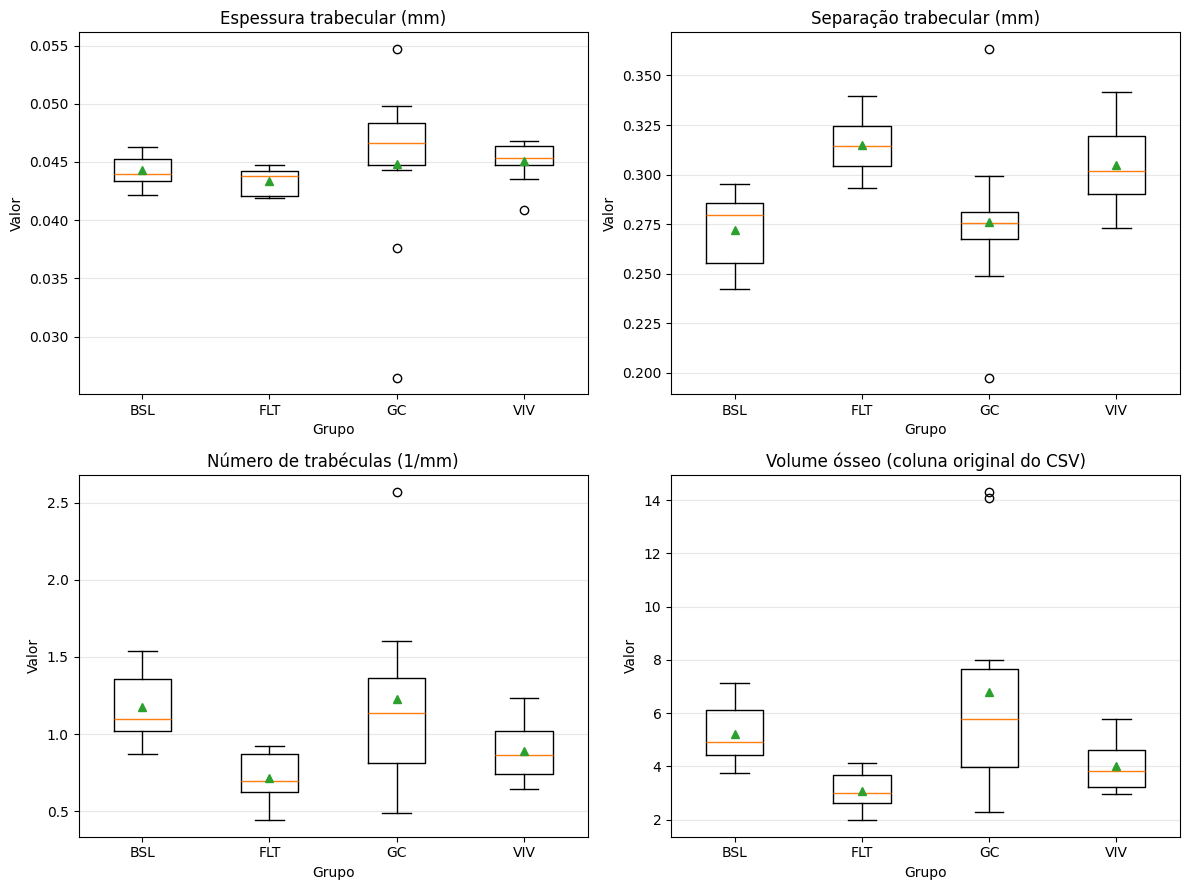

In [33]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, (nome_medida, coluna) in zip(axes, medidas.items()):
    valores_por_grupo = [
        dados.loc[
            dados["grupo_codigo"] == grupo, coluna
        ].dropna().values
        for grupo in ordem_grupos
    ]

    ax.boxplot(
        valores_por_grupo,
        tick_labels=ordem_grupos,
        showmeans=True
    )

    ax.set_title(nome_medida)
    ax.set_xlabel("Grupo")
    ax.set_ylabel("Valor")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [34]:

# Conferir se o dicionário já foi carregado
if "dicionario" in globals():
    print("Dicionário encontrado:")
    display(dicionario.head())
else:
    print("O dicionário ainda não está carregado.")
    print("Precisamos localizar o arquivo CSV do dicionário no Google Drive.")


Dicionário encontrado:


,Acronym,Term,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,pMOI,polar_moment_of_intertia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Imax,Maximum_moment_of_intertia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Imin,Minimum_moment_of_intertia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CSA,cortical_surface_area,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ConnD,connectivity_density,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:

print("Colunas disponíveis no conjunto de dados:")
for coluna in df.columns:
    print("-", coluna)


Colunas disponíveis no conjunto de dados:
- Sample Name
- bone_area_total_area_millimeter_squared
- cortical_thickness_millimeter
- endosteal _perimeter_millimeter
- periosteal_perimeter_millimeter
- bone_volume_total_volume_millimeter_cubed
- connectivity_density_per_millimeter_cubed
- degree_of_anistropy
- trabecular_number_per_millimeter
- trabecular_bone_pattern_factor
- trabecular_separation_millimeter
- trabecular_thickness_millimeter
- grupo_codigo
- animal_id
- regiao_ossea


In [36]:

# Filtrar os animais do grupo GC na região do fêmur distal
gc_distal = df[
    (df["grupo_codigo"] == "GC") &
    (df["regiao_ossea"] == "DistalFemur")
].copy()

colunas_medidas = [
    "Sample Name",
    "animal_id",
    "trabecular_thickness_millimeter",
    "trabecular_separation_millimeter",
    "trabecular_number_per_millimeter",
    "bone_volume_total_volume_millimeter_cubed"
]

# Mostrar os registros ordenados pela espessura trabecular
display(
    gc_distal[colunas_medidas]
    .sort_values("trabecular_thickness_millimeter")
    .reset_index(drop=True)
)


,Sample Name,animal_id,trabecular_thickness_millimeter,trabecular_separation_millimeter,trabecular_number_per_millimeter,bone_volume_total_volume_millimeter_cubed
0,RR1_GC_M34_DistalFemur,M34,0.02649,NaN,NaN,14.32077
1,RR1_GC_M37_DistalFemur,M37,0.03765,0.27582,0.64139,2.41499
2,RR1_GC_M33_DistalFemur,M33,0.04431,0.28118,0.81634,3.61741
3,RR1_GC_M35_DistalFemur,M35,0.04615,0.26754,1.35698,6.26304
4,RR1_GC_M38_DistalFemur,M38,0.04653,0.29921,1.08275,5.03754
5,RR1_GC_M39_DistalFemur,M39,0.04667,0.36348,0.49113,2.29214
6,RR1_GC_M31_DistalFemur,M31,0.04672,0.28081,1.13484,5.30162
7,RR1_GC_M32_DistalFemur,M32,0.04891,0.26843,1.36533,6.67808
8,RR1_GC_M40_DistalFemur,M40,0.04982,0.24882,1.60420,7.99219
9,RR1_GC_M36_DistalFemur,M36,0.05472,0.19763,2.57142,14.07035


In [37]:

medidas_validacao = {
    "Espessura trabecular (mm)": "trabecular_thickness_millimeter",
    "Separação trabecular (mm)": "trabecular_separation_millimeter",
    "Número de trabéculas (1/mm)": "trabecular_number_per_millimeter",
    "BV_TV (coluna original)": "bone_volume_total_volume_millimeter_cubed"
}

# Analisar cada medida separadamente no fêmur distal
dados_distal = df[df["regiao_ossea"] == "DistalFemur"].copy()

resultados_iqr = []

for nome_medida, coluna in medidas_validacao.items():
    for grupo, parte in dados_distal.groupby("grupo_codigo"):
        valores = parte[coluna].dropna()

        if len(valores) == 0:
            continue

        q1 = valores.quantile(0.25)
        q3 = valores.quantile(0.75)
        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        extremos = parte[
            (parte[coluna] < limite_inferior) |
            (parte[coluna] > limite_superior)
        ]

        resultados_iqr.append({
            "Medida": nome_medida,
            "Grupo": grupo,
            "n válido": len(valores),
            "Q1": q1,
            "Q3": q3,
            "Limite inferior": limite_inferior,
            "Limite superior": limite_superior,
            "Possíveis extremos": ", ".join(
                extremos["Sample Name"].astype(str).tolist()
            ) or "Nenhum"
        })

display(pd.DataFrame(resultados_iqr).round(5))


,Medida,Grupo,n válido,Q1,Q3,Limite inferior,Limite superior,Possíveis extremos
0,Espessura trabecular (mm),BSL,10,0.04336,0.04528,0.04047,0.04816,Nenhum
1,Espessura trabecular (mm),FLT,10,0.04207,0.04426,0.03879,0.04755,Nenhum
2,Espessura trabecular (mm),GC,10,0.04477,0.04836,0.03938,0.05375,"RR1_GC_M34_DistalFemur, RR1_GC_M36_DistalFemur..."
3,Espessura trabecular (mm),VIV,10,0.04476,0.04637,0.04235,0.04878,RR1_VIV_M12_DistalFemur
4,Separação trabecular (mm),BSL,10,0.25553,0.28588,0.21000,0.33140,Nenhum
5,Separação trabecular (mm),FLT,10,0.30438,0.32475,0.27382,0.35530,Nenhum
6,Separação trabecular (mm),GC,9,0.26754,0.28118,0.24708,0.30164,"RR1_GC_M36_DistalFemur, RR1_GC_M39_DistalFemur"
7,Separação trabecular (mm),VIV,10,0.29001,0.31962,0.24561,0.36402,Nenhum
8,Número de trabéculas (1/mm),BSL,10,1.01900,1.35731,0.51155,1.86476,Nenhum
9,Número de trabéculas (1/mm),FLT,10,0.62285,0.86880,0.25393,1.23773,Nenhum


In [39]:

# Conferir as colunas disponíveis
print(df.columns.tolist())


['Sample Name', 'bone_area_total_area_millimeter_squared', 'cortical_thickness_millimeter', 'endosteal _perimeter_millimeter', 'periosteal_perimeter_millimeter', 'bone_volume_total_volume_millimeter_cubed', 'connectivity_density_per_millimeter_cubed', 'degree_of_anistropy', 'trabecular_number_per_millimeter', 'trabecular_bone_pattern_factor', 'trabecular_separation_millimeter', 'trabecular_thickness_millimeter', 'grupo_codigo', 'animal_id', 'regiao_ossea']


In [40]:

# Extrair o código do grupo, o animal e a região óssea
df["grupo_codigo"] = df["Sample Name"].str.split("_").str[1]

df["animal_id"] = df["Sample Name"].str.extract(r"_(M\d+)_")

df["regiao_ossea"] = df["Sample Name"].str.extract(
    r"_(CorticalFemur|DistalFemur|FemoralHead|FemoralNeck|Vertebrae)$"
)

# Conferir se as colunas foram criadas
display(df[["Sample Name", "grupo_codigo", "animal_id", "regiao_ossea"]].head())


,Sample Name,grupo_codigo,animal_id,regiao_ossea
0,RR1_BSL_M1_CorticalFemur,BSL,M1,CorticalFemur
1,RR1_BSL_M2_CorticalFemur,BSL,M2,CorticalFemur
2,RR1_BSL_M3_CorticalFemur,BSL,M3,CorticalFemur
3,RR1_BSL_M4_CorticalFemur,BSL,M4,CorticalFemur
4,RR1_BSL_M5_CorticalFemur,BSL,M5,CorticalFemur


In [41]:

animais_verificar = ["M34", "M36", "M39", "M12"]

colunas_verificar = [
    "Sample Name",
    "grupo_codigo",
    "animal_id",
    "regiao_ossea",
    "cortical_thickness_millimeter",
    "trabecular_thickness_millimeter",
    "trabecular_separation_millimeter",
    "trabecular_number_per_millimeter",
    "bone_volume_total_volume_millimeter_cubed"
]

casos = df[df["animal_id"].isin(animais_verificar)]

display(
    casos[colunas_verificar]
    .sort_values(["animal_id", "regiao_ossea"])
    .reset_index(drop=True)
    .round(5)
)


,Sample Name,grupo_codigo,animal_id,regiao_ossea,cortical_thickness_millimeter,trabecular_thickness_millimeter,trabecular_separation_millimeter,trabecular_number_per_millimeter,bone_volume_total_volume_millimeter_cubed
0,RR1_VIV_M12_CorticalFemur,VIV,M12,CorticalFemur,0.23454,NaN,NaN,NaN,NaN
1,RR1_VIV_M12_DistalFemur,VIV,M12,DistalFemur,NaN,0.04090,0.32207,0.72886,2.98100
2,RR1_VIV_M12_FemoralHead,VIV,M12,FemoralHead,NaN,0.09506,0.10955,5.52632,52.53417
3,RR1_VIV_M12_FemoralNeck,VIV,M12,FemoralNeck,0.25837,NaN,NaN,NaN,NaN
4,RR1_VIV_M12_Vertebrae,VIV,M12,Vertebrae,NaN,0.04960,0.11944,6.71402,33.30195
5,RR1_GC_M34_CorticalFemur,GC,M34,CorticalFemur,NaN,NaN,NaN,NaN,NaN
6,RR1_GC_M34_DistalFemur,GC,M34,DistalFemur,NaN,0.02649,NaN,NaN,14.32077
7,RR1_GC_M34_Vertebrae,GC,M34,Vertebrae,NaN,0.05049,0.12114,6.69408,33.79938
8,RR1_GC_M36_CorticalFemur,GC,M36,CorticalFemur,0.24238,NaN,NaN,NaN,NaN
9,RR1_GC_M36_DistalFemur,GC,M36,DistalFemur,NaN,0.05472,0.19763,2.57142,14.07035


In [42]:

# Conferir apenas os registros do fêmur distal
colunas_distal = [
    "Sample Name",
    "bone_area_total_area_millimeter_squared",
    "cortical_thickness_millimeter",
    "bone_volume_total_volume_millimeter_cubed",
    "connectivity_density_per_millimeter_cubed",
    "degree_of_anistropy",
    "trabecular_number_per_millimeter",
    "trabecular_bone_pattern_factor",
    "trabecular_separation_millimeter",
    "trabecular_thickness_millimeter"
]

casos_distal = df[
    (df["animal_id"].isin(["M34", "M36", "M39", "M12"])) &
    (df["regiao_ossea"] == "DistalFemur")
]

display(casos_distal[colunas_distal].to_string(index=False))


'            Sample Name  bone_area_total_area_millimeter_squared  cortical_thickness_millimeter  bone_volume_total_volume_millimeter_cubed  connectivity_density_per_millimeter_cubed  degree_of_anistropy  trabecular_number_per_millimeter  trabecular_bone_pattern_factor  trabecular_separation_millimeter  trabecular_thickness_millimeter\nRR1_VIV_M12_DistalFemur                                      NaN                            NaN                                    2.98100                                   105.3170              1.17303                           0.72886                        42.02016                           0.32207                          0.04090\n RR1_GC_M34_DistalFemur                                      NaN                            NaN                                   14.32077                                        NaN                  NaN                               NaN                             NaN                               NaN                       

In [44]:
for arquivo in os.listdir("/content"):
    if arquivo.endswith((".xlsx", ".csv")):
        print(arquivo)


LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv
LSDS-130_microCT_Cahill_RR1_MicroCt_Data_SUBMITTED.xlsx
LSDS-130_microCT_micro_computed_tomography_Data_Dictionary.csv


In [45]:
caminho_csv = "/content/LSDS-130_microCT_Cahill_microCT_TRANSFORMED.csv"
caminho_excel = "/content/LSDS-130_microCT_Cahill_RR1_MicroCt_Data_SUBMITTED.xlsx"
caminho_dicionario = "/content/LSDS-130_microCT_micro_computed_tomography_Data_Dictionary.csv"

df_csv = pd.read_csv(caminho_csv)
dicionario = pd.read_csv(caminho_dicionario)

excel = pd.ExcelFile(caminho_excel)

print("Abas da planilha original:")
print(excel.sheet_names)

print("\nColunas do dicionário:")
print(dicionario.columns.tolist())


Abas da planilha original:
['Sheet1', 'Sheet2']

Colunas do dicionário:
['Acronym', 'Term', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19']


In [46]:

display(
    dicionario[
        dicionario.astype(str)
        .apply(
            lambda coluna: coluna.str.contains(
                "BV/TV|bone volume|bone_volume|volume fraction",
                case=False,
                na=False
            )
        )
        .any(axis=1)
    ].to_string(index=False)
)


'Acronym                     Term  Unnamed: 2  Unnamed: 3  Unnamed: 4  Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8  Unnamed: 9  Unnamed: 10  Unnamed: 11  Unnamed: 12  Unnamed: 13  Unnamed: 14  Unnamed: 15  Unnamed: 16  Unnamed: 17  Unnamed: 18  Unnamed: 19\n     BV              bone_volume         NaN         NaN         NaN         NaN         NaN         NaN         NaN         NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN\n  BV_TV bone_volume_total_volume         NaN         NaN         NaN         NaN         NaN         NaN         NaN         NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN          NaN'

In [47]:

# Conferir os nomes das abas da planilha original
print(excel.sheet_names)

# Verificar a estrutura de cada aba
for aba in excel.sheet_names:
    temp = pd.read_excel(caminho_excel, sheet_name=aba)
    print(f"\nAba: {aba}")
    print("Dimensões:", temp.shape)
    print("Colunas:", temp.columns.tolist()[:12])
    display(temp.head(3))


['Sheet1', 'Sheet2']

Aba: Sheet1
Dimensões: (40, 52)
Colunas: ['Unnamed: 0', 'Group', 'Sample', 'BV/TV', 'Tb.Th.', 'Tb.Sp.', 'Tb.N.', 'Tb.Pf.', 'DA', 'Conn.D.', 'Unnamed: 10', 'Unnamed: 11']


,Unnamed: 0,Group,Sample,BV/TV,Tb.Th.,Tb.Sp.,Tb.N.,Tb.Pf.,DA,Conn.D.,...,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50,Unnamed: 51
0,NaN,BL,D1,33.06831,0.057418,0.142701,5.759186,16.54602,2.424220,2201.936,...,GC,GC,GC,GC,GC,GC,GC,GC,GC,GC
1,NaN,BL,D2,29.78839,0.051818,0.142594,5.748695,16.11478,1.931125,2205.364,...,57.31903,54.37678,55.28507,NaN,54.04162,58.98074,NaN,55.32724,55.11248,53.90497
2,NaN,BL,D3,30.66512,0.054132,0.138699,5.664927,20.00287,2.208493,2317.657,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Aba: Sheet2
Dimensões: (29, 42)
Colunas: ['Site', 'Measure', 'BL_1', 'BL_2', 'BL_3', 'BL_4', 'BL_5', 'BL_6', 'BL_7', 'BL_8', 'BL_9', 'BL_10']


,Site,Measure,BL_1,BL_2,BL_3,BL_4,BL_5,BL_6,BL_7,BL_8,...,GC_1,GC_2,GC_3,GC_4,GC_5,GC_6,GC_7,GC_8,GC_9,GC_10
0,Cortical Femur,BA_TA,51.483500,54.275800,53.817500,53.603300,53.626700,52.457800,54.850400,54.491900,...,57.319030,54.376780,55.285070,NaN,54.041620,58.980740,NaN,55.327240,55.112480,53.904970
1,Cortical Femur,Ct_Th,0.208846,0.221782,0.216016,0.213607,0.206721,0.216123,0.221371,0.220334,...,0.234375,0.226450,0.226072,NaN,0.207235,0.242377,NaN,0.222783,0.226918,0.219028
2,Cortical Femur,E_Pm,3.734664,3.660836,3.610342,3.682542,3.394830,3.669057,3.558244,3.635168,...,3.502916,3.778612,3.882606,3.671393,3.397639,3.423937,3.648471,3.559001,3.628503,3.657760


In [48]:

# Carregar a Sheet1 original
sheet1 = pd.read_excel(caminho_excel, sheet_name="Sheet1")

# Mostrar todas as colunas relevantes para BV/TV
display(
    sheet1[["Group", "Sample", "BV/TV", "Tb.Th.", "Tb.Sp.", "Tb.N.", "Tb.Pf.", "DA", "Conn.D."]]
    .to_string(index=False)
)

# Conferir as primeiras linhas e os nomes de amostra
print("\nGrupos encontrados:", sheet1["Group"].dropna().unique())
print("Amostras encontradas:", sheet1["Sample"].dropna().unique()[:15])


'Group Sample    BV/TV   Tb.Th.   Tb.Sp.    Tb.N.   Tb.Pf.       DA  Conn.D.\n   BL     D1 33.06831 0.057418 0.142701 5.759186 16.54602 2.424220 2201.936\n   BL     D2 29.78839 0.051818 0.142594 5.748695 16.11478 1.931125 2205.364\n   BL     D3 30.66512 0.054132 0.138699 5.664927 20.00287 2.208493 2317.657\n   BL     D4 32.71269 0.050206 0.126042 6.515636 14.65513 1.801626 2514.057\n   BL     D5 28.83117 0.052733 0.152435 5.467383 17.96129 2.545083 2072.928\n   BL     D6 32.81522 0.052361 0.132032 6.267106 17.62271 2.095250 2733.183\n   BL     D7 28.96643 0.049624 0.135710 5.837168 19.06923 2.261591 2333.774\n   BL     D8 30.21567 0.051834 0.142847 5.829295 24.65105 2.501454 2861.950\n   BL     D9 32.97855 0.053140 0.134611 6.205955 20.26601 1.976460 2731.581\n   BL    D10 35.57904 0.052337 0.125443 6.798069 16.02022 1.560963 3114.301\n  VIV    D11 34.99291 0.056469 0.136048 6.196819 17.14544 2.564448 2314.289\n  VIV    D12 33.30195 0.049601 0.119439 6.714023 22.48430 2.162210 3049.265


Grupos encontrados: ['BL' 'VIV' 'FL' 'GC']
Amostras encontradas: ['D1' 'D2' 'D3' 'D4' 'D5' 'D6' 'D7' 'D8' 'D9' 'D10' 'D11' 'D12' 'D14'
 'D15' 'D16']


In [49]:

# Mostrar todas as amostras do grupo GC na Sheet1
gc_sheet1 = sheet1[sheet1["Group"] == "GC"]

display(
    gc_sheet1[
        ["Group", "Sample", "BV/TV", "Tb.Th.", "Tb.Sp.", "Tb.N.", "Tb.Pf.", "DA", "Conn.D."]
    ].to_string(index=False)
)


'Group Sample    BV/TV   Tb.Th.   Tb.Sp.    Tb.N.   Tb.Pf.       DA  Conn.D.\n   GC    D31 34.83408 0.054917 0.133549 6.343032 17.70898 1.637228 2296.693\n   GC    D32 31.61910 0.050479 0.139092 6.263837 15.09429 2.434032 2263.367\n   GC    D33 19.01580 0.033399 0.151911 5.693596 34.50178 2.075819 4397.081\n   GC    D34 33.79938 0.050491 0.121138 6.694083 20.98260 2.226322 2622.910\n   GC    D35 35.49676 0.049056 0.116996 7.236008 16.42794 2.552256 2601.240\n   GC    D36 41.33779 0.058013 0.112543 7.125560 13.22955 1.874618 2506.884\n   GC    D37 31.12641 0.048643 0.130123 6.398943 23.13345 1.367445 3225.256\n   GC    D38 22.72876 0.044714 0.161279 5.083156 22.58809 2.101668 2967.052\n   GC    D39 24.72696 0.046503 0.158623 5.317285 21.69789 2.375152 2704.912\n   GC    D40 30.61888 0.049341 0.137776 6.205596 22.87690 1.775115 2639.781'

In [50]:

sheet2 = pd.read_excel(caminho_excel, sheet_name="Sheet2")

# Conferir as medidas do fêmur distal para os animais GC
medidas_gc = sheet2[
    (sheet2["Site"] == "Distal Femur") &
    (sheet2["Measure"].isin(["BV_TV", "Tb_Th", "Tb_Sp", "Tb_N"]))
]

display(
    medidas_gc[
        ["Site", "Measure"] +
        [f"GC_{i}" for i in range(1, 11)]
    ].to_string(index=False)
)


'        Site Measure    GC_1    GC_2    GC_3     GC_4    GC_5     GC_6    GC_7    GC_8    GC_9   GC_10\nDistal Femur   BV_TV 5.30162 6.67808 3.61741 14.32077 6.26304 14.07035 2.41499 5.03754 2.29214 7.99219\nDistal Femur    Tb_N 1.13484 1.36533 0.81634      NaN 1.35698  2.57142 0.64139 1.08275 0.49113 1.60420\nDistal Femur   Tb_Sp 0.28081 0.26843 0.28118      NaN 0.26754  0.19763 0.27582 0.29921 0.36348 0.24882\nDistal Femur   Tb_Th 0.04672 0.04891 0.04431  0.02649 0.04615  0.05472 0.03765 0.04653 0.04667 0.04982'